# Notebook 2: Databehandling og logistisk regresjon

In [148]:
# Importerer nødvendige libraries
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [149]:
# Leser inn filen med datasettet og lagrer det som en DataFrame
kundeklager_df = pd.read_csv('Kundeklager.csv', low_memory=False)

In [150]:
# Sjekker antall rader og kolonner 
kundeklager_df.shape

(1282355, 18)

In [151]:
# Printer ut kolonnenavnene
print(kundeklager_df.columns)

Index(['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue',
       'Consumer complaint narrative', 'Company public response', 'Company',
       'State', 'ZIP code', 'Tags', 'Consumer consent provided?',
       'Submitted via', 'Date sent to company', 'Company response to consumer',
       'Timely response?', 'Consumer disputed?', 'Complaint ID'],
      dtype='str')


In [152]:
# Ser hvordan dataene ser ut ved å vise de fem første radene
kundeklager_df.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,05/10/2019,Checking or savings account,Checking account,Managing an account,Problem using a debit or ATM card,NaN,NaN,NAVY FEDERAL CREDIT UNION,FL,328XX,Older American,NaN,Web,05/10/2019,In progress,Yes,NaN,3238275
1,05/10/2019,Checking or savings account,Other banking product or service,Managing an account,Deposits and withdrawals,NaN,NaN,BOEING EMPLOYEES CREDIT UNION,WA,98204,NaN,NaN,Referral,05/10/2019,Closed with explanation,Yes,NaN,3238228
2,05/10/2019,Debt collection,Payday loan debt,Communication tactics,Frequent or repeated calls,NaN,NaN,CURO Intermediate Holdings,TX,751XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3237964
3,05/10/2019,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Old information reappears or never goes away,NaN,NaN,Ad Astra Recovery Services Inc,LA,708XX,NaN,NaN,Web,05/10/2019,Closed with explanation,Yes,NaN,3238479
4,05/10/2019,Checking or savings account,Checking account,Managing an account,Banking errors,NaN,NaN,ALLY FINANCIAL INC.,AZ,85205,NaN,NaN,Postal mail,05/10/2019,In progress,Yes,NaN,3238460


In [153]:
# Sjekker antall unike kunder 
print(kundeklager_df['Complaint ID'].nunique())

# Antallet er likt med antall kolonner i datasettet

1282355


In [154]:
# Lager en ny tabell som bare inneholder klager med fritekst 
fritekst_df = kundeklager_df[kundeklager_df['Consumer complaint narrative'].notna()]

# Sjekker hvor mange klager dette gjelder
print(len(fritekst_df))   

383564


In [155]:
# Lager en ny tabell som videre bare inneholder klager i produktfamilien "Credit card or prepaid card"
kredittkort_df = fritekst_df[fritekst_df['Product'] == 'Credit card or prepaid card']

# Sjekker hvor mange klager dette gjelder
print(len(kredittkort_df))   

21379


In [156]:
# Skriver ut alle kategoriene (issues) innad i kredittkortklager og antall klager
print(kredittkort_df['Issue'].value_counts())

Issue
Problem with a purchase shown on your statement                                     4604
Other features, terms, or problems                                                  3060
Fees or interest                                                                    2994
Problem when making payments                                                        2208
Closing your account                                                                1716
Getting a credit card                                                               1715
Advertising and marketing, including promotional offers                             1691
Trouble using your card                                                              877
Incorrect information on your report                                                 528
Problem with a purchase or transfer                                                  468
Struggling to pay your bill                                                          372
Trouble using t

In [157]:
# Lager en liste med navnene på 7 største kategoriene (Issue)
topp7 = kredittkort_df['Issue'].value_counts().head(7).index

# Lager en ny tabell med de 7 kategoriene med flest klager
topp7_df = kredittkort_df[kredittkort_df['Issue'].isin(topp7)]

# Skriver ut hvor mange klager som er med i den nye tabellen
print('Klager i de syv største kategoriene:', len(topp7_df))   

# Skriver ut hvor stor andel av de totale kredittkortklager de 7 kategoriene utgjør
print('Andel av alle kredittkortklager:', round(len(topp7_df) / len(kredittkort_df) * 100, 1), '%') 

# Skriver ut hvr mange kategorier som ble utelatt
print('Utelatte kategorier:', kredittkort_df['Issue'].nunique() - 7)   

Klager i de syv største kategoriene: 17988
Andel av alle kredittkortklager: 84.1 %
Utelatte kategorier: 15


In [158]:
# Fjerner klager med nøyaktig samme tekst
topp7_df = topp7_df.drop_duplicates(subset='Consumer complaint narrative')

# Skriver ut hvor mange klager som er igjen at duplikatene er fjernet
print(len(topp7_df))

17912


In [159]:
# Skriver ut alle problemer (issues) innad i de syv største kredittkortklagene og antall klager
print(topp7_df['Issue'].value_counts())

Issue
Problem with a purchase shown on your statement            4599
Other features, terms, or problems                         3059
Fees or interest                                           2992
Problem when making payments                               2148
Closing your account                                       1714
Getting a credit card                                      1712
Advertising and marketing, including promotional offers    1688
Name: count, dtype: int64


In [160]:
# Deler hver fritekstklage opp i ord og lagrer antall ord i en ny kolonne
topp7_df['antall_ord'] = topp7_df['Consumer complaint narrative'].str.split().str.len()

# Skriver ut statistikk om antall ord per klage
print(lengde.describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

count    17912.000000
mean       247.347867
std        253.913927
min          3.000000
10%         60.000000
25%        102.000000
50%        183.000000
75%        303.250000
90%        492.900000
95%        673.000000
99%       1170.890000
max       5735.000000
Name: Consumer complaint narrative, dtype: float64


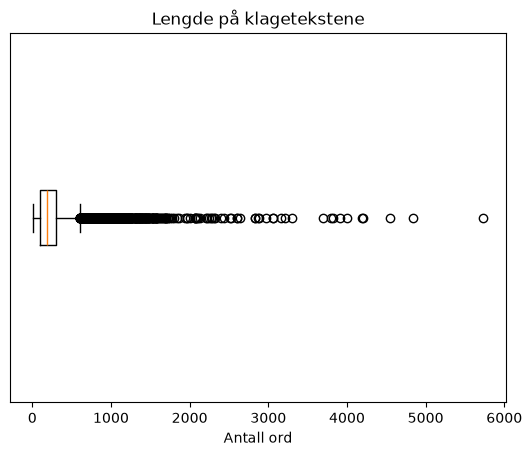

In [161]:
# Lager et liggende boxplot som viser fordelingen av antall ord per klage
plt.boxplot(topp7_df['antall_ord'], orientation='horizontal')

# Fjerner 1-tallet på y-aksen fordi det ikke betyr noe
plt.yticks([])
           
plt.xlabel('Antall ord')
plt.title('Lengde på klagetekstene')
plt.show()

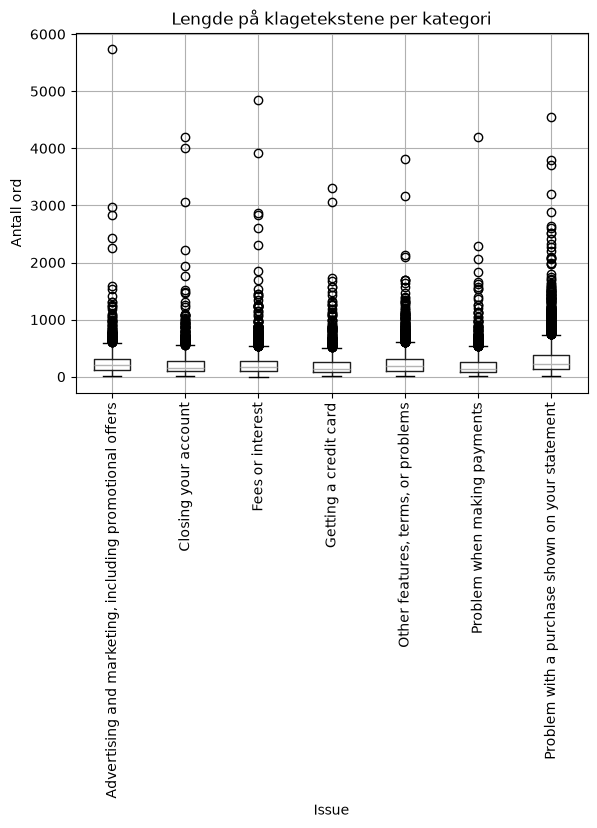

In [162]:
# Lager et boxplot for hver kategori som viser antall ord i fritekstklagene
topp7_df.boxplot(column=['antall_ord'], by='Issue', rot=90)

# Fjerner den automatiske overskriften som legges til
plt.suptitle('')

plt.ylabel('Antall ord')
plt.title('Lengde på klagetekstene per kategori')
plt.show()

In [163]:
# Lagrer tabellen som en egen CSV-fil
topp7_df.to_csv('topp7.csv', index=False)

In [164]:
# Lagrer klagetekstene i variabelen X (det modellen skal lese)
X = topp7_df['Consumer complaint narrative'] 

# Lagrer problemkategorien i y (det modellen skal gjette)
y = topp7_df['Issue']  

# Deler klagene inn i 80% treningssett og 20% testsett
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

# Tar 250 klager fra treningssettet og legger dem i et valideringssett
train_X, valid_X, train_y, valid_y = train_test_split(train_X, train_y, test_size=250, stratify=train_y, random_state=1)

# Skriver ut antall klager i de ulike delsettene
print('Treningssett:', len(train_X))      
print('Valideringssett:', len(valid_X))   
print('Testsett:', len(test_X))          

Treningssett: 14079
Valideringssett: 250
Testsett: 3583


In [165]:
# Lagre trenings-, validerings- og testsettet som hver sin CSV-fil
# Velger hvilke kolonner som skal være med i filene
kolonner = ['Complaint ID', 'Issue', 'Consumer complaint narrative']

topp7_df.loc[train_X.index, kolonner].to_csv('treningssett.csv', index=False)
topp7_df.loc[valid_X.index, kolonner].to_csv('valideringssett.csv', index=False)
topp7_df.loc[test_X.index, kolonner].to_csv('testsett.csv', index=False)

In [166]:
# Sjekker hvordan klagene ser ut

# Velger ut 5 tilfeldige klager fra treningssettet med færre enn 80 ord
korte_klager = train_X[train_X.str.split().str.len() < 80].sample(5, random_state=1)

# Går gjennom de 5 klagene én etter én og henter radnummer og tilhørende klagetekst
for indeks, tekst in korte_klager.items():
    # Skriver ut kategorien til klagen
    print('Kategori:', train_y[indeks])
    # Skriver ut klageteksten ved å dele teksten opp i linjer på maks 100 tegn
    print(textwrap.fill(tekst, width=100))
    # Skriver ut skillelinje
    print('_' * 100)

Kategori: Getting a credit card
was told they are not going to do a hard pull on m y credit score. it t hey did.. they lied ...
____________________________________________________________________________________________________
Kategori: Closing your account
XXXX closed all of my credit card accounts after pulling my credit report saying I had too many
recent inquiries. I have a spotless credit history and have never missed a payment and I rarely even
carry a balance on my credit cards. I 've been with XXXX for over 10 years and still have an auto
loan with them.
____________________________________________________________________________________________________
Kategori: Getting a credit card
I received a Netspend Mastercard in the mail. I never applied for this. Since then my checking/Debit
Card and XXXX Credit Card has been hacked. I tried calling the phone numbers for this Netspend but
have been unable to get in contact with anyone for further information. I do not and did not ope

In [167]:
# Lager et verktøy som gjør om tekst til tall 
tf_idf_vektor = TfidfVectorizer()

# Lærer hvilke ord som finnes i klagene i treningssettet og gjør dem om til tall
train_X_vek = tf_idf_vektor.fit_transform(train_X)   
# Gjør om klagene i valideringssettet til tall med samme ordforråd
valid_X_vek = tf_idf_vektor.transform(valid_X)  
# Gjør om klagene i testsettet til tall med samme ordforråd
test_X_vek = tf_idf_vektor.transform(test_X)          

# Skriver ut antall klager og antall ulike ord i ordforrådet
print(train_X_vek.shape)   

(14079, 23404)


In [168]:
# Lager en logistisk regresjonsmodell som skal gjette kategorien til en klage
# Modellen kan bruke opptil 1000 runder på å finne de beste vektene
reg = LogisticRegression(max_iter=1000)

# Trener modellen på treningssettet
reg.fit(train_X_vek, train_y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [169]:
# Lar moodellen gjette kategori for de 250 klagene i valideringssettet
# Bruker valideringssett for å teste at alt funker
valid_pred = reg.predict(valid_X_vek)

# Skriver ut rapport om hvor godt modellen traff
print(classification_report(valid_y, valid_pred))

                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.60      0.39      0.47        23
                                   Closing your account       0.56      0.62      0.59        24
                                       Fees or interest       0.76      0.88      0.81        42
                                  Getting a credit card       0.78      0.58      0.67        24
                     Other features, terms, or problems       0.59      0.53      0.56        43
                           Problem when making payments       0.70      0.63      0.67        30
        Problem with a purchase shown on your statement       0.76      0.89      0.82        64

                                               accuracy                           0.70       250
                                              macro avg       0.68      0.65      0.66       250
                            

In [170]:
# Lager en balansert logistisk regresjonsmodell som vekter alle kategoriene likt
reg = LogisticRegression(max_iter=1000, class_weight='balanced')

# Trener modellen på treningssettet 
reg.fit(train_X_vek, train_y)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [171]:
# Lar modellen gjette kategorien for hver av de 250 klagene i valideringssettet
valid_pred = reg.predict(valid_X_vek)

# Skriver ut rapport på hvor godt modellen traff
print(classification_report(valid_y, valid_pred))

                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.59      0.57      0.58        23
                                   Closing your account       0.51      0.75      0.61        24
                                       Fees or interest       0.73      0.88      0.80        42
                                  Getting a credit card       0.75      0.75      0.75        24
                     Other features, terms, or problems       0.61      0.40      0.48        43
                           Problem when making payments       0.68      0.63      0.66        30
        Problem with a purchase shown on your statement       0.84      0.81      0.83        64

                                               accuracy                           0.70       250
                                              macro avg       0.67      0.68      0.67       250
                            

In [172]:
# Lager en modell som alltid gjetter den kategorien som har flest klager
baseline = DummyClassifier(strategy='most_frequent')

# Finner ut hvilken kategori som er vanligst i treningssettet
baseline.fit(train_X_vek, train_y)

# Gjetter den samme kategorien for alle klagene i testsettet
baseline_pred = baseline.predict(test_X_vek)

# Skriver ut rapporten for hvor godt baselinen traff
print(classification_report(test_y, baseline_pred, zero_division=0))

                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.00      0.00      0.00       338
                                   Closing your account       0.00      0.00      0.00       343
                                       Fees or interest       0.00      0.00      0.00       598
                                  Getting a credit card       0.00      0.00      0.00       342
                     Other features, terms, or problems       0.00      0.00      0.00       612
                           Problem when making payments       0.00      0.00      0.00       430
        Problem with a purchase shown on your statement       0.26      1.00      0.41       920

                                               accuracy                           0.26      3583
                                              macro avg       0.04      0.14      0.06      3583
                            

In [173]:
# Logistisk regresjon (balansert)
# Modellen gjetter kategorien for hver klage i testsettet
test_pred = reg.predict(test_X_vek)

# Skriver ut rapporten for hvor godt modellen traff
print(classification_report(test_y, test_pred))

                                                         precision    recall  f1-score   support

Advertising and marketing, including promotional offers       0.59      0.64      0.61       338
                                   Closing your account       0.61      0.76      0.67       343
                                       Fees or interest       0.76      0.70      0.73       598
                                  Getting a credit card       0.68      0.81      0.74       342
                     Other features, terms, or problems       0.60      0.45      0.51       612
                           Problem when making payments       0.69      0.78      0.73       430
        Problem with a purchase shown on your statement       0.86      0.81      0.84       920

                                               accuracy                           0.71      3583
                                              macro avg       0.68      0.71      0.69      3583
                            

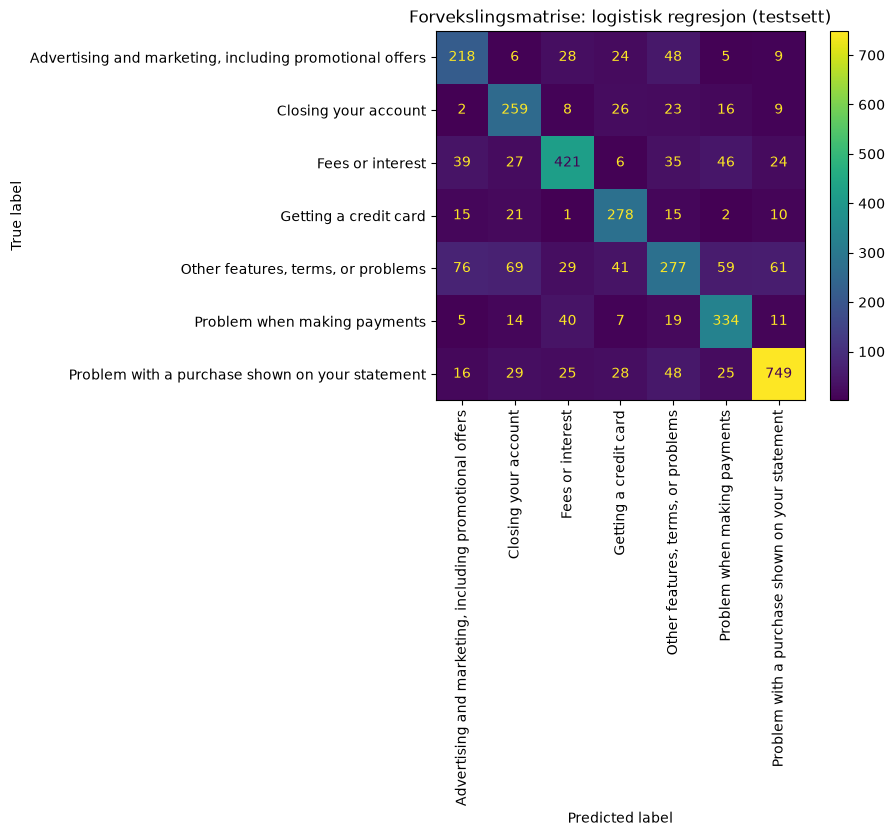

In [174]:
# Lager en forvekslingsmatrise som viser hvor godt modellen gjorde det på testsettet
ConfusionMatrixDisplay.from_predictions(test_y, test_pred, xticks_rotation=90)

plt.title('Forvekslingsmatrise: logistisk regresjon (testsett)')
plt.show()

In [176]:
# Lager en kopi av klagene i testsettet og lagrer det i ny variabel
resultater = topp7_df.loc[test_X.index, ['Complaint ID', 'Issue', 'Consumer complaint narrative']].copy()

# Legger til en ny kolonne med kategorien modellen gjettet for hver klage
resultater['lr_pred'] = test_pred

# Lagrer tabellen som en CSV-fil
resultater.to_csv('resultater_lr.csv', index=False)